# Makale Yeniden Üretimi: *Efficient Data Representation by Selecting Prototypes with Importance Weights* (ProtoDash, Gurumoorthy ve ark., 2019)

**Makale:** K. S. Gurumoorthy, A. Dhurandhar, G. Cecchi, C. Aggarwal. *Efficient Data Representation by Selecting Prototypes with Importance Weights.* IEEE ICDM 2019. [arXiv:1707.01212](https://arxiv.org/abs/1707.01212) · Kod: [IBM AIX360 `ProtoDashExplainer`](https://github.com/Trusted-AI/AIX360)
**Temel yöntem:** B. Kim, R. Khanna, O. Koyejo. *Examples are not Enough, Learn to Criticize!* NeurIPS 2016 (MMD-critic).

**Konu 26 (Prototipler ve Eleştiriler) · Seçenek 3: Geliştirme/Modifikasyon.** MMD-critic prototipleri eşit ağırlıklı seçer. ProtoDash (1) her prototipe bir **önem ağırlığı** verir, (2) hedef küme ile aday havuzunu **ayırır** (hedef ile havuz farklı veri olabilir), (3) ProtoGreedy'ye göre **çok daha hızlıdır**. Makalenin iddiası: ağırlıklı seçim, özellikle hedef küme havuzdan farklı dağıldığında (skew) daha iyi temsil eder.

**Bu defterde yapılanlar**

| Bölüm | Ne yapılıyor | Makaledeki karşılığı |
|---|---|---|
| 1 | Amaç fonksiyonu ve algoritmalar (ProtoDash, ProtoGreedy, MMD-critic, K-Medoids benzeri) | Bölüm 3-4 |
| 2 | **Orijinal MNIST skew deneyinin** yeniden üretimi: doğruluk, süre, ağırlık dağılımı | Deneyler (skewli MNIST) |
| 3 | **Kendi verimde** (Kaggle German Credit) aynı deney ve okunabilir prototip/eleştiri tabloları | Yeni katkı |
| 4 | Duyarlılık: çekirdek genişliği γ ve prototip sayısı m | Yeni katkı |
| 5 | **Uzantı:** "düşük ağırlıklı prototipler eleştiri gibi davranır" iddiasını sınama | Makalenin yorumu, ölçülmemişti |
| 6 | Sonuç ve tartışma (sayılar çıktılardan otomatik yazılır) | |

**Kapsam notu (makaleden farklarım).**
1. Makalenin tam deney kurgusu (örneklem boyutları, tekrar sayısı) birebir verilmiyor. Boyutları kendim seçtim, sayılar makaledekiyle aynı çıkmaz, **eğilimler** karşılaştırılır.
2. ProtoDash'i kendim kodladım (gradyan ile aday seçimi, ardından negatif olmayan en küçük kareler). AIX360 kullanılmıyor.
3. K-Medoids için gerçek PAM yerine **KMeans + en yakın havuz noktası** yaklaşığı kullandım.
4. "Tutuyor mu" tablolarındaki eşikler (örn. "0,02'den az fark") **bana ait**, makaleden gelmiyor.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import nnls
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_openml
from sklearn.metrics.pairwise import rbf_kernel, euclidean_distances
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

SEED = 0
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
METHODS = ["ProtoDash", "ProtoGreedy", "MMD-critic (L2C)", "K-Medoids~", "Rastgele"]
COLORS = {"ProtoDash": "#d62728", "ProtoGreedy": "#ff7f0e", "MMD-critic (L2C)": "#1f77b4",
          "K-Medoids~": "#2ca02c", "Rastgele": "#7f7f7f"}

## 1) Amaç fonksiyonu ve algoritmalar

Hedef küme $X^{(1)}$ ($n$ örnek), aday havuzu $X^{(2)}$ ($N$ aday) ve çekirdek $k$ (RBF) olsun. Havuzun çekirdek matrisi $K_{ij}=k(p_i,p_j)$, her adayın hedef kümeye ortalama benzerliği $\mu_j=\frac1n\sum_{x\in X^{(1)}}k(p_j,x)$.

**MMD-critic:** eşit ağırlıklı $m$ prototip seçer, $\mathrm{MMD}^2=\frac1{n^2}\sum k(x,x')-\frac2{nm}\sum k(x,p)+\frac1{m^2}\sum k(p,p')$ değerini açgözlü azaltır.

**ProtoDash:** ağırlık vektörü $w\ge 0$ için $\;\ell(w)=w^\top\mu-\tfrac12 w^\top K_{SS}\,w\;$ fonksiyonunu büyütür. Bu, ağırlıklı $\mathrm{MMD}^2$'yi (sabit terim hariç) küçültmeye denktir. Her adımda, mevcut $w$ altında gradyanı $\nabla_j=\mu_j-(Kw)_j$ en büyük olan aday eklenir, sonra $w$ yeniden çözülür (negatif olmayan en küçük kareler). Gradyanla seçim, ProtoGreedy'nin her aday için ayrı QP çözmesinden çok daha ucuzdur.

**Ağırlıklı MMD²** (tüm yöntemleri karşılaştırmak için, sabit $\bar k_{xx}$ dahil):
$$\mathrm{MMD}^2(w)=\bar k_{xx}-2\,w^\top\mu_S+w^\top K_{SS}\,w,\qquad \textstyle\sum_i w_i=1.$$

**Tanık fonksiyonu** (eleştiriler için): $\;\mathrm{witness}(x)=\frac1n\sum_{x'\in X^{(1)}}k(x,x')-\sum_i w_i\,k(x,p_i)$. $|\mathrm{witness}|$ büyük olan noktalar prototiplerin iyi temsil etmediği yerlerdir (**eleştiriler**).

In [2]:
# ---------------------------------------------------------------------------
# Algoritmalar
# ---------------------------------------------------------------------------
def median_gamma(X, rng, n=400):
    """Medyan sezgisi: γ = 1 / (2 · medyan(‖xi − xj‖²)), köşegen hariç."""
    sub = X[rng.choice(len(X), min(n, len(X)), replace=False)]
    d2 = euclidean_distances(sub, squared=True)
    return 1.0 / (2 * np.median(d2[np.triu_indices(len(sub), 1)]))


def solve_w(K, mu, S):
    """w ≥ 0 için  max wᵀμ − ½ wᵀKw  (S üzerinde). Cholesky + NNLS."""
    KS = K[np.ix_(S, S)] + 1e-8 * np.eye(len(S))
    L = np.linalg.cholesky(KS)
    w, _ = nnls(L.T, np.linalg.solve(L, mu[S]))
    return w


def objective(K, mu, S, w):
    return float(w @ mu[S] - 0.5 * w @ K[np.ix_(S, S)] @ w)


def protodash(K, mu, m):
    S, w = [], np.zeros(0)
    for _ in range(m):
        grad = np.asarray(mu - (K[:, S] @ w if S else 0.0), dtype=float).copy()
        if S:
            grad[S] = -np.inf
        S.append(int(np.argmax(grad)))
        w = solve_w(K, mu, S)
    return np.array(S), w


def protogreedy(K, mu, m):
    """Her adım için TÜM adaylarda QP çözer: aynı hedef, çok daha yavaş."""
    S = []
    for _ in range(m):
        best, bj = -np.inf, None
        for j in range(len(K)):
            if j in S:
                continue
            T = S + [j]
            val = objective(K, mu, T, solve_w(K, mu, T))
            if val > best:
                best, bj = val, j
        S.append(bj)
    return np.array(S), solve_w(K, mu, S)


def mmd_critic_protos(K, mu, m):
    """Eşit ağırlıklı açgözlü MMD² azaltma (MMD-critic / L2C prototip seçimi), hedef ve havuz ayrık."""
    n = len(K)
    S = []
    for _ in range(m):
        cand = np.setdiff1d(np.arange(n), S)
        k = len(S) + 1
        cross = (mu[S].sum() if S else 0.0) + mu[cand]
        ss = K[cand, cand].copy()
        if S:
            ss += K[np.ix_(S, S)].sum() + 2 * K[np.ix_(cand, S)].sum(axis=1)
        S.append(int(cand[np.argmin(-2 * cross / k + ss / k ** 2)]))
    return np.array(S)


def kmedoids_like(Xp, X1, m, seed=0):
    centers = KMeans(n_clusters=m, n_init=3, random_state=seed).fit(X1).cluster_centers_
    return np.array([int(np.argmin(((Xp - c) ** 2).sum(1))) for c in centers])


def mmd2(K, mu, kxx, S, w=None):
    """Ağırlıklı MMD² (hedef kümeye göre). w verilmezse eşit ağırlık."""
    w = np.ones(len(S)) / len(S) if w is None else w / w.sum()
    return float(kxx - 2 * w @ mu[S] + w @ K[np.ix_(S, S)] @ w)


# ---------------------------------------------------------------------------
# Skewli örnekleme ve deney koşucusu
# ---------------------------------------------------------------------------
def skewed_sample(rng, idx_pool, labels, d, s, n):
    """n örneklik küme: %s hedef sınıf d, kalanı diğer sınıflardan."""
    n_t = int(round(n * s / 100))
    t = rng.choice(idx_pool[labels[idx_pool] == d], n_t, replace=True)
    o = (rng.choice(idx_pool[labels[idx_pool] != d], n - n_t, replace=True)
         if n_t < n else np.array([], dtype=int))
    return np.concatenate([t, o])


def run_methods(rng, X, y, pool_idx, A_idx, B_idx, d, s, kern, n_pool, n_sample, m, with_greedy=True):
    """Bir skew düzeyi için tüm yöntemleri çalıştırır; satır listesi döndürür.
    acc: yeni skewli örneklemde 1-NN doğruluğu · mmd2: hedef kümeye ağırlıklı MMD² · share: seçimin hedef sınıfa düşen payı
    (ProtoDash/ProtoGreedy'de ağırlıkla, diğerlerinde sayıyla)."""
    pidx = rng.choice(pool_idx, min(n_pool, len(pool_idx)), replace=False)
    Xp, yp = X[pidx], y[pidx]
    X1 = X[skewed_sample(rng, A_idx, y, d, s, n_sample)]
    ie = skewed_sample(rng, B_idx, y, d, s, n_sample)
    Xe, ye = X[ie], y[ie]
    K, mu = kern(Xp, Xp), kern(Xp, X1).mean(axis=1)
    kxx = kern(X1, X1).mean()
    rows = []

    def add(name, S, w, t):
        acc = KNeighborsClassifier(1).fit(Xp[S], yp[S]).score(Xe, ye)
        if w is not None and w.sum() > 0:
            share = float(w[yp[S] == d].sum() / w.sum())
        else:
            share = float((yp[S] == d).mean())
        rows.append(dict(method=name, skew=s, acc=acc, mmd2=mmd2(K, mu, kxx, S, w), share=share, time=t))

    t = time.time(); S, w = protodash(K, mu, m); add("ProtoDash", S, w, time.time() - t)
    if with_greedy:
        t = time.time(); S, w = protogreedy(K, mu, m); add("ProtoGreedy", S, w, time.time() - t)
    t = time.time(); S = mmd_critic_protos(K, mu, m); add("MMD-critic (L2C)", S, None, time.time() - t)
    t = time.time(); S = kmedoids_like(Xp, X1, m, SEED); add("K-Medoids~", S, None, time.time() - t)
    add("Rastgele", rng.choice(len(Xp), m, replace=False), None, 0.0)
    return rows


def pivot(df, col, ndigits=3):
    p = df.pivot_table(index="method", columns="skew", values=col, aggfunc="mean")
    return p.reindex([mm for mm in METHODS if mm in p.index]).round(ndigits)

## 2) Orijinal deney: skewli MNIST

**Kurgu (makaledeki gibi).** Hedef rakam $d$ seçilir. Hedef küme $X^{(1)}$: $s\%$ oranında rakam $d$, kalanı diğer rakamlar. Aday havuzu $X^{(2)}$ ise **tüm rakamlardan** (skewsiz) gelir. Her yöntem havuzdan $m$ prototip seçer, sonra taze bir skewli örneklemde seçilen prototiplerle **1-NN sınıflandırma doğruluğu** ölçülür. $s$ arttıkça hedef küme havuzdan uzaklaşır; ağırlıklı seçim burada avantajlı olmalıdır.

**Makalenin iddiaları (özet):** (a) skew arttıkça ProtoDash'in kazancı büyür, düşük skew'de K-Medoids rekabetçidir; (b) ProtoDash doğrulukta ProtoGreedy'ye yakındır ama çok daha hızlıdır; (c) %100 skewde ağırlık hedef sınıfta toplanır.

Bu hücre MNIST'i OpenML'den indirir (internet gerekir) ve en uzun hücredir (birkaç dakika).

In [3]:
N_SUB, N_POOL, N_SAMPLE, M, R = 10000, 500, 200, 10, 8
SKEWS = [30, 50, 70, 90, 100]

mn = fetch_openml("mnist_784", version=1, as_frame=False)
sel = rng.choice(len(mn.data), min(N_SUB, len(mn.data)), replace=False)
Xm, ym = mn.data[sel] / 255.0, mn.target[sel].astype(int)

perm = rng.permutation(len(Xm))
n_pool_all = int(0.6 * len(Xm))
pool_m, rest = perm[:n_pool_all], perm[n_pool_all:]
A_m, B_m = rest[:len(rest) // 2], rest[len(rest) // 2:]      # A: hedef küme örneklemi · B: değerlendirme örneklemi
gamma_m = median_gamma(Xm[pool_m], rng)
kern_m = lambda P, Q: rbf_kernel(P, Q, gamma=gamma_m)
print("MNIST:", Xm.shape, "| havuz:", len(pool_m), "| A:", len(A_m), "| B:", len(B_m), "| γ = %.5f" % gamma_m)

rows = []
t0 = time.time()
for s in SKEWS:
    for r in range(R):
        d = int(rng.integers(10))
        rows += [dict(rep=r, d=d, **row) for row in
                 run_methods(rng, Xm, ym, pool_m, A_m, B_m, d, s, kern_m, N_POOL, N_SAMPLE, M)]
    print(f"  skew %{s} tamam ({time.time() - t0:.0f} sn)")
res_m = pd.DataFrame(rows)

MNIST: (10000, 784) | havuz: 6000 | A: 2000 | B: 2000 | γ = 0.00481
  skew %30 tamam (6 sn)
  skew %50 tamam (12 sn)
  skew %70 tamam (17 sn)
  skew %90 tamam (24 sn)
  skew %100 tamam (29 sn)


### 2.1) Doğruluk, skew arttıkça (makalenin ana şekli)

**Ortalama 1-NN doğruluğu** (satır: yöntem, sütun: skew %)

skew,30,50,70,90,100
method,,,,,
ProtoDash,0.378,0.465,0.589,0.816,0.876
ProtoGreedy,0.394,0.514,0.613,0.841,0.895
MMD-critic (L2C),0.399,0.491,0.611,0.794,0.896
K-Medoids~,0.515,0.572,0.666,0.846,0.931
Rastgele,0.326,0.386,0.372,0.384,0.369


**Ortalama MMD²** (küçük iyi)

skew,30,50,70,90,100
method,,,,,
ProtoDash,0.0154,0.0155,0.0163,0.0138,0.0163
ProtoGreedy,0.0148,0.0149,0.0150,0.0134,0.0152
MMD-critic (L2C),0.0164,0.0159,0.0162,0.0145,0.0172
K-Medoids~,0.0233,0.0244,0.0260,0.0274,0.0268
Rastgele,0.0449,0.0490,0.0611,0.1001,0.1050


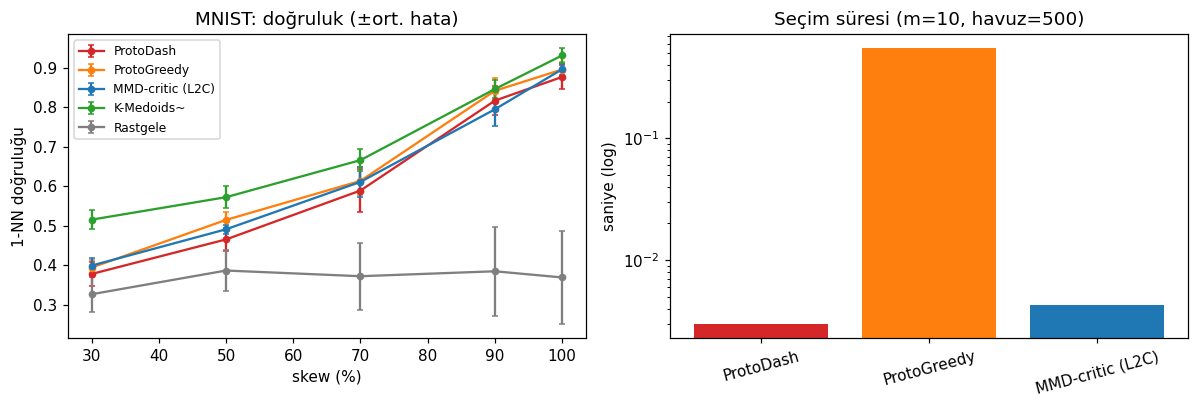

In [4]:
display(Markdown("**Ortalama 1-NN doğruluğu** (satır: yöntem, sütun: skew %)"))
display(pivot(res_m, "acc"))
display(Markdown("**Ortalama MMD²** (küçük iyi)"))
display(pivot(res_m, "mmd2", 4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for mm in METHODS:
    g = res_m[res_m.method == mm].groupby("skew").acc
    ax[0].errorbar(SKEWS, g.mean().values, yerr=g.std().values / np.sqrt(R), marker="o", ms=4, capsize=2,
                   label=mm, color=COLORS[mm])
ax[0].set(xlabel="skew (%)", ylabel="1-NN doğruluğu", title="MNIST: doğruluk (±ort. hata)")
ax[0].legend(fontsize=8)
tm = res_m[res_m.method.isin(["ProtoDash", "ProtoGreedy", "MMD-critic (L2C)"])].groupby("method").time.mean()
tm = tm.reindex([mm for mm in METHODS if mm in tm.index])
ax[1].bar(tm.index, tm.values, color=[COLORS[i] for i in tm.index])
ax[1].set(yscale="log", ylabel="saniye (log)", title=f"Seçim süresi (m={M}, havuz={N_POOL})")
ax[1].tick_params(axis="x", labelrotation=15)
plt.tight_layout(); plt.show()

### 2.2) %100 skewde ağırlıklar hangi sınıfa gidiyor?
Makale: hedef kümede yalnızca rakam $d$ varken ProtoDash'in ağırlığı $d$ sınıfındaki prototiplere toplanmalı, diğer sınıflardan seçilenler küçük ağırlık almalı.

In [5]:
sh = res_m[res_m["skew"] == 100].groupby("method").share.mean().reindex(METHODS).dropna().round(3)
display(Markdown("**Seçimin hedef sınıfa düşen payı, %100 skew** (ProtoDash/ProtoGreedy: ağırlıkla, diğerleri: sayıyla)"))
display(sh.to_frame("hedef sınıf payı"))

**Seçimin hedef sınıfa düşen payı, %100 skew** (ProtoDash/ProtoGreedy: ağırlıkla, diğerleri: sayıyla)

,hedef sınıf payı
method,
ProtoDash,0.742
ProtoGreedy,0.789
MMD-critic (L2C),0.700
K-Medoids~,0.925
Rastgele,0.138


### 2.3) Makale iddiası ↔ bu yeniden üretim
Tablodaki **eşikler bana aittir** (makalede sayısal eşik yok). Değerler yukarıdaki sonuçlardan hesaplanır.

In [6]:
acc = pivot(res_m, "acc", 6)
tmean = res_m.groupby("method").time.mean()
gain30 = acc.loc["ProtoDash", 30] - acc.loc["K-Medoids~", 30]
gain100 = acc.loc["ProtoDash", 100] - acc.loc["K-Medoids~", 100]
gap_pg = float((acc.loc["ProtoDash"] - acc.loc["ProtoGreedy"]).abs().mean())
speed = float(tmean["ProtoGreedy"] / tmean["ProtoDash"])
share100 = float(sh["ProtoDash"])

claims_m = pd.DataFrame([
    ("(a) Skew arttıkça ProtoDash'in K-Medoids'e göre kazancı büyür", "kazanç(%100) > kazanç(%30)",
     f"{gain30:+.3f} → {gain100:+.3f}", gain100 > gain30),
    ("(b1) ProtoDash ≈ ProtoGreedy doğrulukta", "ortalama |fark| < 0,02", f"{gap_pg:.3f}", gap_pg < 0.02),
    ("(b2) ProtoDash, ProtoGreedy'den çok daha hızlı", "hız oranı > 5×", f"{speed:.1f}×", speed > 5),
    ("(c) %100 skewde ağırlık hedef sınıfta toplanır", "pay > 0,80", f"{share100:.3f}", share100 > 0.80),
], columns=["Makale iddiası", "Ölçüt (benim eşiğim)", "Bu yeniden üretimde", "Tutuyor mu"])
claims_m

,Makale iddiası,Ölçüt (benim eşiğim),Bu yeniden üretimde,Tutuyor mu
0,(a) Skew arttıkça ProtoDash'in K-Medoids'e gör...,kazanç(%100) > kazanç(%30),-0.138 → -0.054,True
1,(b1) ProtoDash ≈ ProtoGreedy doğrulukta,"ortalama |fark| < 0,02",0.027,False
2,"(b2) ProtoDash, ProtoGreedy'den çok daha hızlı",hız oranı > 5×,186.4×,True
3,(c) %100 skewde ağırlık hedef sınıfta toplanır,"pay > 0,80",0.742,False


## 3) Kendi verim: Kaggle German Credit

Aynı deneyi tablo verisine taşıyorum: 1000 kredi başvurusu, `Risk` = *good/bad*. **Hedef sınıf = `bad`** (≈%30), yani "riskli müşteri" bölümünü temsil edecek prototipler arıyorum. Görüntü verisinden farklı olarak burada her prototip **okunabilir bir müşteri satırıdır**: ProtoDash'in ağırlıkları ve MMD-critic eleştirileri yorumlanabilir.

**Özellikler:** sayısal (Age, Job, log Credit amount, Duration, Sex) standartlaştırılır; kategorik (Housing, Saving accounts, Checking account, Purpose) one-hot. RBF çekirdeği, medyan sezgisiyle γ.

In [14]:
def veri_hazirla(ad="veri.csv"):
    """veri.csv defterle aynı klasörde olmalı. Yoksa Colab'da yükleme penceresi açılır."""
    if os.path.exists(ad):
        return
    try:
        from google.colab import files          # yalnızca Colab'da vardır
        print(f"{ad} bulunamadı. Açılan pencereden veri.csv dosyasını seçin.")
        files.upload()
    except ImportError:
        pass
    if not os.path.exists(ad):
        raise FileNotFoundError(f"{ad} bulunamadı. Dosyayı bu defterle aynı klasöre koyup hücreyi yeniden çalıştırın.")

veri_hazirla("veri.csv")
raw = pd.read_csv("veri.csv", keep_default_na=False)
raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")]).reset_index(drop=True)

num = pd.DataFrame({"Age": raw["Age"], "Job": raw["Job"], "log Credit amount": np.log(raw["Credit amount"]),
                    "Duration": raw["Duration"], "Sex": (raw["Sex"] == "male").astype(int)}).astype(float)
cat = pd.get_dummies(raw[["Housing", "Saving accounts", "Checking account", "Purpose"]], dtype=int).astype(float)
Xg = np.hstack([StandardScaler().fit_transform(num), cat.values])
yg = (raw["Risk"] == "bad").astype(int).values            # hedef sınıf: bad = 1

idx_all = np.arange(len(Xg))
pool_g, rest_g = train_test_split(idx_all, train_size=0.6, stratify=yg, random_state=SEED)
A_g, B_g = train_test_split(rest_g, test_size=0.5, stratify=yg[rest_g], random_state=SEED)
gamma_g = median_gamma(Xg[pool_g], rng)
kern_g = lambda P, Q: rbf_kernel(P, Q, gamma=gamma_g)
print("German:", Xg.shape, "| bad oranı: %.3f" % yg.mean(), "| havuz:", len(pool_g), "| A:", len(A_g), "| B:", len(B_g),
      "| γ = %.4f" % gamma_g)

German: (1000, 25) | bad oranı: 0.300 | havuz: 600 | A: 200 | B: 200 | γ = 0.0370


### 3.1) Canlı çıktı: "riskli müşteri" kümesinin ağırlıklı prototipleri ve eleştirileri
Hedef küme: A kümesindeki tüm `bad` müşteriler. Havuz: eğitim payındaki **tüm** müşteriler (good + bad). ProtoDash hedef kümeyi temsil eden 8 müşteri ve ağırlık seçer. Eleştiriler, prototiplerle hedef kümenin yoğunluğu arasındaki farkın en büyük olduğu hedef küme noktalarıdır (en büyük $|\mathrm{witness}|$).

In [8]:
SHOW = ["Age", "Sex", "Job", "Housing", "Saving accounts", "Checking account", "Credit amount", "Duration", "Purpose", "Risk"]
X1_idx = A_g[yg[A_g] == 1]
X1 = Xg[X1_idx]
Xp = Xg[pool_g]
Kp, mup = kern_g(Xp, Xp), kern_g(Xp, X1).mean(axis=1)
S, w = protodash(Kp, mup, 8)
wn = w / w.sum()

proto = raw.loc[pool_g[S], SHOW].copy()
proto.insert(0, "ağırlık %", (100 * wn).round(1))
proto = proto.sort_values("ağırlık %", ascending=False)
display(Markdown("**ProtoDash prototipleri** (ağırlığa göre sıralı; ağırlığı 0 olanlar seçildi ama katkısı kalmadı)"))
display(proto)

wit = kern_g(X1, X1).mean(axis=1) - kern_g(X1, Xp[S]) @ wn
top = np.argsort(-np.abs(wit))[:5]
crit = raw.loc[X1_idx[top], SHOW].copy()
crit.insert(0, "witness", wit[top].round(3))
display(Markdown("**Eleştiriler** (|witness| en büyük `bad` müşteriler; witness > 0: prototipler bu bölgeyi yetersiz temsil ediyor, witness < 0: prototipler bu bölgeye gereğinden fazla ağırlık veriyor)"))
display(crit)
print(f"Prototiplerin hedef sınıf (bad) ağırlık payı: {wn[yg[pool_g[S]] == 1].sum():.2f}  |  "
      f"havuzdaki bad oranı: {yg[pool_g].mean():.2f}")

**ProtoDash prototipleri** (ağırlığa göre sıralı; ağırlığı 0 olanlar seçildi ama katkısı kalmadı)

,ağırlık %,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
321,28.5,32,male,2,own,little,little,1938,24,radio/TV,bad
995,15.4,31,female,1,own,little,no account,1736,12,furniture/equipment,good
952,11.7,28,female,2,rent,quite rich,moderate,4113,24,car,bad
17,10.1,25,male,2,own,unknown/no account,little,8072,30,business,good
788,10.0,50,male,2,free,little,moderate,6224,48,education,bad
979,9.8,25,male,2,rent,moderate,moderate,1264,15,car,bad
444,9.2,30,female,3,own,little,moderate,5096,48,furniture/equipment,bad
75,5.2,66,male,3,free,little,little,1526,12,car,good


**Eleştiriler** (|witness| en büyük `bad` müşteriler; witness > 0: prototipler bu bölgeyi yetersiz temsil ediyor, witness < 0: prototipler bu bölgeye gereğinden fazla ağırlık veriyor)

,witness,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
963,-0.040,35,male,2,own,quite rich,no account,2397,24,radio/TV,bad
228,-0.036,22,male,2,own,little,no account,1478,9,radio/TV,bad
935,-0.035,30,male,3,own,moderate,moderate,1919,30,radio/TV,bad
405,-0.032,22,male,2,own,little,moderate,2039,24,radio/TV,bad
470,-0.032,22,male,2,rent,moderate,moderate,3092,24,radio/TV,bad


Prototiplerin hedef sınıf (bad) ağırlık payı: 0.69  |  havuzdaki bad oranı: 0.30


### 3.2) Skew deneyi German Credit'te
Aynı kurgu: $s\%$ `bad` içeren bir hedef küme, havuz skewsiz. $s=30$ doğal orana yakındır. Metrik 1-NN doğruluğu (yeni skewli örneklemde), MMD² ve ağırlığın `bad` sınıfına düşen payı.

tamam (31 sn)


**Ortalama 1-NN doğruluğu**

skew,30,50,70,90,100
method,,,,,
ProtoDash,0.637,0.559,0.507,0.540,0.505
ProtoGreedy,0.645,0.548,0.484,0.488,0.419
MMD-critic (L2C),0.650,0.542,0.498,0.459,0.483
K-Medoids~,0.656,0.553,0.497,0.511,0.477
Rastgele,0.619,0.528,0.456,0.388,0.293


**Ortalama MMD²** (küçük iyi)

skew,30,50,70,90,100
method,,,,,
ProtoDash,0.0075,0.0078,0.0080,0.0086,0.0090
ProtoGreedy,0.0082,0.0094,0.0095,0.0100,0.0106
MMD-critic (L2C),0.0102,0.0105,0.0109,0.0114,0.0118
K-Medoids~,0.0262,0.0227,0.0260,0.0257,0.0266
Rastgele,0.0491,0.0569,0.0594,0.0669,0.0633


**Seçimin `bad` sınıfına düşen payı**

skew,30,50,70,90,100
method,,,,,
ProtoDash,0.321,0.430,0.429,0.536,0.493
ProtoGreedy,0.288,0.355,0.374,0.502,0.445
MMD-critic (L2C),0.287,0.360,0.373,0.433,0.480
K-Medoids~,0.213,0.333,0.293,0.420,0.433
Rastgele,0.267,0.247,0.267,0.300,0.287


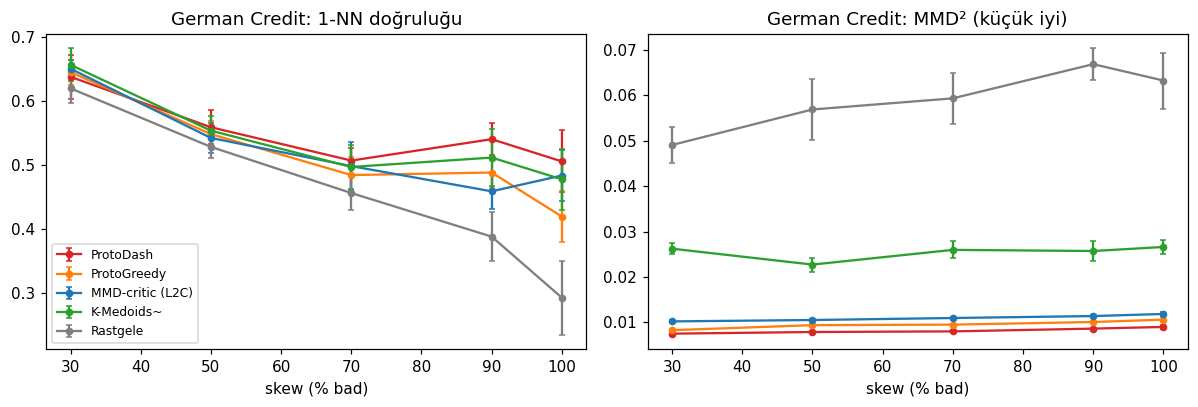

In [9]:
N_POOL_G, N_SAMPLE_G, M_G, R_G = 300, 100, 10, 15
SKEWS_G = [30, 50, 70, 90, 100]
rows = []
t0 = time.time()
for s in SKEWS_G:
    for r in range(R_G):
        rows += [dict(rep=r, **row) for row in
                 run_methods(rng, Xg, yg, pool_g, A_g, B_g, 1, s, kern_g, N_POOL_G, N_SAMPLE_G, M_G)]
print(f"tamam ({time.time() - t0:.0f} sn)")
res_g = pd.DataFrame(rows)
display(Markdown("**Ortalama 1-NN doğruluğu**"))
display(pivot(res_g, "acc"))
display(Markdown("**Ortalama MMD²** (küçük iyi)"))
display(pivot(res_g, "mmd2", 4))
display(Markdown("**Seçimin `bad` sınıfına düşen payı**"))
display(pivot(res_g, "share"))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for mm in METHODS:
    for a, col, ttl in [(ax[0], "acc", "German Credit: 1-NN doğruluğu"), (ax[1], "mmd2", "German Credit: MMD² (küçük iyi)")]:
        g = res_g[res_g.method == mm].groupby("skew")[col]
        a.errorbar(SKEWS_G, g.mean().values, yerr=g.std().values / np.sqrt(R_G), marker="o", ms=4, capsize=2,
                   label=mm, color=COLORS[mm])
        a.set(xlabel="skew (% bad)", title=ttl)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4) Duyarlılık: çekirdek genişliği γ ve prototip sayısı m
**4.1** γ'yı medyan sezgisinin 0,25× … 4× katlarına getiriyorum (hedef: A'daki `bad` müşteriler, havuz: tüm eğitim payı, m=10). Seçilen kümenin değişimini (Jaccard), ağırlığı sıfırdan büyük prototip sayısını ve ProtoDash MMD²'sinin aynı çekirdekte rastgele seçime oranını izliyorum.

In [10]:
def gamma_sweep(mults, m=10, n_rand=30):
    base = None
    out = []
    for g in mults:
        kk = lambda P, Q, g=g: rbf_kernel(P, Q, gamma=g * gamma_g)
        K, mu, kxx = kk(Xp, Xp), kk(Xp, X1).mean(axis=1), kk(X1, X1).mean()
        S, w = protodash(K, mu, m)
        base = set(S) if g == 1 else base
        rnd = np.mean([mmd2(K, mu, kxx, rng.choice(len(Xp), m, replace=False)) for _ in range(n_rand)])
        out.append(dict(gamma_kat=g, S=set(S), nnz=int((w > 1e-6).sum()), mmd2_pd=mmd2(K, mu, kxx, S, w), mmd2_rastgele=rnd))
    for o in out:
        o["jaccard_1x"] = len(o["S"] & base) / len(o["S"] | base)
        o["oran_pd/rastgele"] = o["mmd2_pd"] / o["mmd2_rastgele"]
    return pd.DataFrame(out).drop(columns="S")

gs = gamma_sweep([0.25, 0.5, 1, 2, 4])
gs.round(4)

,gamma_kat,nnz,mmd2_pd,mmd2_rastgele,jaccard_1x,oran_pd/rastgele
0,0.25,10,0.0012,0.0218,0.0526,0.0566
1,0.50,10,0.0034,0.0401,0.0526,0.0845
2,1.00,10,0.0080,0.0654,1.0000,0.1226
3,2.00,10,0.0225,0.0986,0.3333,0.2286
4,4.00,10,0.0462,0.1204,0.0526,0.3834


**4.2** Prototip sayısı m arttıkça MMD² (ağırlıklı ProtoDash, eşit ağırlıklı MMD-critic, rastgele ortalaması). Makale: ağırlıklı seçim aynı m için daha küçük MMD² vermeli.

,ProtoDash,MMD_critic,Rastgele
m,,,
2,0.06697,0.07631,0.24637
5,0.02358,0.02816,0.11558
10,0.00802,0.01177,0.06447
20,0.00315,0.00414,0.04680
40,0.00109,0.00179,0.03403


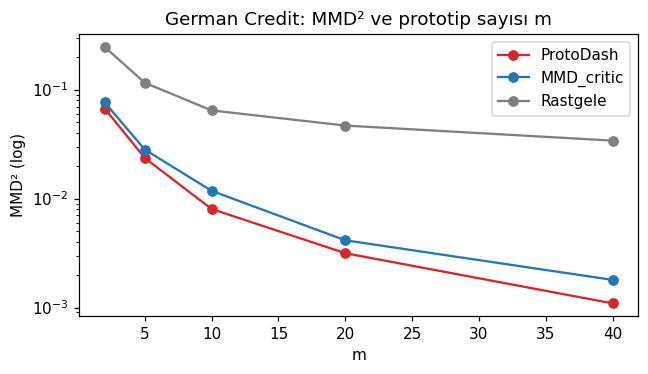

In [11]:
MS = [2, 5, 10, 20, 40]
kxx_g = kern_g(X1, X1).mean()
rec = []
for m in MS:
    S, w = protodash(Kp, mup, m)
    Sc = mmd_critic_protos(Kp, mup, m)
    rnd = np.mean([mmd2(Kp, mup, kxx_g, rng.choice(len(Xp), m, replace=False)) for _ in range(30)])
    rec.append(dict(m=m, ProtoDash=mmd2(Kp, mup, kxx_g, S, w), MMD_critic=mmd2(Kp, mup, kxx_g, Sc), Rastgele=rnd))
ms_tab = pd.DataFrame(rec).set_index("m")
display(ms_tab.round(5))
ms_tab.plot(marker="o", logy=True, figsize=(6, 3.5), color=["#d62728", "#1f77b4", "#7f7f7f"],
            title="German Credit: MMD² ve prototip sayısı m")
plt.ylabel("MMD² (log)"); plt.tight_layout(); plt.show()

## 5) Uzantı: "düşük ağırlıklı prototipler eleştiri gibi davranır" iddiası
Makale, ağırlıkların bir önem sırası verdiğini ve düşük ağırlıklı prototiplerin hedef dağılımın **kenarını** (eleştirileri) temsil ettiğini söyler. Bunu ölçen bir deney sunulmamış. Ölçüm: hedef kümedeki yerel yoğunluk $\mu(x)=\frac1n\sum k(x,x')$. İddia doğruysa yüksek ağırlıklı prototipler yoğun bölgede (büyük $\mu$), düşük ağırlıklılar ve eleştiriler seyrek bölgede (küçük $\mu$) olmalıdır.

20 farklı havuz altörneğinde (m=15, hedef: %100 `bad`) şunlara bakıyorum: ağırlık ile $\mu$ arasındaki Spearman korelasyonu; en yüksek üçte bir / en düşük üçte bir ağırlıklı prototiplerin, MMD-critic eleştirilerinin ve rastgele havuz noktalarının ortalama $\mu$ değeri. **Dikkat:** ProtoDash zaten gradyanı büyük (yani $\mu$ büyük) adayları önce seçtiği için pozitif korelasyon kısmen yapısaldır; asıl soru, düşük ağırlıklıların rastgele noktalardan da seyrek olup olmadığıdır.

In [12]:
R5, M5 = 20, 15
rec = []
for r in range(R5):
    pidx = rng.choice(pool_g, 300, replace=False)
    Xp5 = Xg[pidx]
    X15 = Xg[skewed_sample(rng, A_g, yg, 1, 100, 100)]
    K5, mu5 = kern_g(Xp5, Xp5), kern_g(Xp5, X15).mean(axis=1)
    S5, w5 = protodash(K5, mu5, M5)
    order = np.argsort(-w5, kind="stable")
    third = M5 // 3
    wn5 = w5 / w5.sum()
    wit5 = kern_g(X15, X15).mean(axis=1) - kern_g(X15, Xp5[S5]) @ wn5
    dens15 = kern_g(X15, X15).mean(axis=1)
    rho = spearmanr(w5, mu5[S5]).correlation
    rec.append(dict(rho=rho,
                    mu_yuksek=mu5[S5][order[:third]].mean(), mu_dusuk=mu5[S5][order[-third:]].mean(),
                    mu_elestiri=dens15[np.argsort(-np.abs(wit5))[:5]].mean(), mu_rastgele=mu5.mean()))
e5 = pd.DataFrame(rec)
tab5 = pd.DataFrame({
    "ortalama μ (hedef yoğunluğu)": [e5.mu_yuksek.mean(), e5.mu_dusuk.mean(), e5.mu_elestiri.mean(), e5.mu_rastgele.mean()],
    "std": [e5.mu_yuksek.std(), e5.mu_dusuk.std(), e5.mu_elestiri.std(), e5.mu_rastgele.std()]},
    index=["yüksek ağırlıklı prototipler (üst 1/3)", "düşük ağırlıklı prototipler (alt 1/3)",
           "MMD-critic eleştirileri (hedef noktaları)", "rastgele havuz noktası"]).round(4)
display(tab5)
print(f"Spearman(ağırlık, μ): ortalama {e5.rho.mean():+.2f}  |  pozitif çıkan altörneklem: {(e5.rho > 0).sum()}/{R5}")

,ortalama μ (hedef yoğunluğu),std
yüksek ağırlıklı prototipler (üst 1/3),0.6223,0.0209
düşük ağırlıklı prototipler (alt 1/3),0.4884,0.0369
MMD-critic eleştirileri (hedef noktaları),0.6311,0.0232
rastgele havuz noktası,0.5761,0.0077


Spearman(ağırlık, μ): ortalama +0.70  |  pozitif çıkan altörneklem: 20/20


## 6) Sonuç ve tartışma
Aşağıdaki metin, yukarıdaki çıktılardan **otomatik** yazılır. Cümleler sonuca göre değişir.

In [13]:
def pm(x):
    return f"{x.mean():.3f}"

accg = pivot(res_g, "acc", 6)
tg = res_g.groupby("method").time.mean()
gain30g = accg.loc["ProtoDash", 30] - accg.loc["K-Medoids~", 30]
gain100g = accg.loc["ProtoDash", 100] - accg.loc["K-Medoids~", 100]
vs_critic = pivot(res_g, "mmd2", 6)
mmd_better = bool((vs_critic.loc["ProtoDash"] < vs_critic.loc["MMD-critic (L2C)"]).all())
mmd_better_n = int((vs_critic.loc["ProtoDash"] < vs_critic.loc["MMD-critic (L2C)"]).sum())
share_g = pivot(res_g, "share", 6)
n_ok = int(claims_m["Tutuyor mu"].sum())
yuksek_gt_dusuk = e5.mu_yuksek.mean() > e5.mu_dusuk.mean()
dusuk_lt_rast = e5.mu_dusuk.mean() < e5.mu_rastgele.mean()
sabit = int((gs.jaccard_1x[gs.gamma_kat.isin([0.5, 2])] >= 0.5).sum())

metin = f"""
**1. Orijinal bulgu (MNIST).** Makalenin dört iddiasından {n_ok}/4'ü bu yeniden üretimde tuttu (tablo 2.3, eşikler bana ait). Skew 30'dan 100'e çıkarken ProtoDash'in K-Medoids~'e doğruluk farkı {gain30:+.3f} → {gain100:+.3f} ({"ProtoDash her iki ucta da K-Medoids~'in altında kaldı, yalnızca fark kapandı" if (gain30 < 0 and gain100 < 0) else "ProtoDash skewli uçta öne geçti" if gain100 > 0 else "karışık"}). ProtoDash ile ProtoGreedy doğruluğu arasındaki ortalama fark {gap_pg:.3f}, ProtoDash {speed:.1f} kat hızlı. %100 skewde ProtoDash ağırlığının {share100:.2f}'si hedef sınıfa gitti. {"Makalenin ana mesajı (ağırlıklı ve hızlı seçimin skewli hedefi iyi temsil etmesi) büyük ölçüde yeniden üretildi." if n_ok >= 3 else "İddiaların bir kısmı bu kurguda yeniden üretilemedi; boyut ve tekrar seçimlerim makaleden farklı olduğu için bunu yöntemin çürütüldüğü şeklinde okumamak gerekir."}

**2. Kendi verime taşıma (German Credit, hedef = riskli müşteri).** Skew 30'dan 100'e ProtoDash'in K-Medoids~'e göre doğruluk kazancı {gain30g:+.3f} → {gain100g:+.3f}. MMD² açısından ProtoDash, eşit ağırlıklı MMD-critic'ten {mmd_better_n}/5 skew düzeyinde daha iyi {"(her düzeyde)" if mmd_better else ""}. %100 skewde ProtoDash'in bad sınıfına verdiği ağırlık payı {share_g.loc["ProtoDash", 100]:.2f} (havuzdaki bad oranı {yg[pool_g].mean():.2f}). Tablo verisinde yararı şu: prototipler okunabilir müşteri satırları ve ağırlık "bu müşteri hedef grubu ne kadar temsil ediyor" sorusunu yanıtlıyor (bölüm 3.1).

**3. Duyarlılık.** γ'yı yarıya/iki katına getirince seçilen kümenin Jaccard benzerliği {"yüksek (≥0,5)" if sabit == 2 else "düşük: seçim γ'ya duyarlı"} ({sabit}/2 durumda ≥ 0,5). Yani prototiplerin kimliği **çekirdek genişliğine bağlı**, bu bir tasarım seçimi olarak raporlanmalı. m arttıkça tüm yöntemlerde MMD² azalıyor; ProtoDash m=10'da {ms_tab.loc[10, "ProtoDash"]:.4f}, MMD-critic {ms_tab.loc[10, "MMD_critic"]:.4f}, rastgele {ms_tab.loc[10, "Rastgele"]:.4f}.

**4. Uzantı: düşük ağırlık = eleştiri mi?** Ağırlık ile hedef yoğunluğu arasındaki Spearman {e5.rho.mean():+.2f} (altörneklemlerin {(e5.rho > 0).sum()}/{R5}'sinde pozitif). Yüksek ağırlıklı prototiplerin yoğunluğu {e5.mu_yuksek.mean():.3f}, düşük ağırlıklılarınki {e5.mu_dusuk.mean():.3f}, eleştirilerinki {e5.mu_elestiri.mean():.3f}, rastgele noktalarınki {e5.mu_rastgele.mean():.3f}. {"Düşük ağırlıklılar yüksek ağırlıklılardan daha seyrek bölgede: iddia yönüyle doğrulandı." if yuksek_gt_dusuk else "Düşük ağırlıklılar yüksek ağırlıklılardan daha seyrek değil: iddia bu veride doğrulanmadı."} {"Ayrıca rastgele bir noktadan da seyrek, yani gerçekten kenardalar." if (yuksek_gt_dusuk and dusuk_lt_rast) else "Düşük ağırlıklılar rastgele havuz noktasından daha seyrek değil, dolayısıyla 'eleştiri gibi davranıyor' demek zor."} (Bu sonuç kısmen yapısal: ProtoDash önce yoğun bölgeyi seçer.)

**Sınırlar ve dürüstlük notları**
* Deney boyutlarını (havuz, örneklem, tekrar sayısı) kendim seçtim; sayılar makaleninkiyle birebir aynı değil.
* ProtoDash'i kendi kodumla yazdım, AIX360 ile karşılaştırmadım. K-Medoids gerçek PAM değil, KMeans + en yakın havuz noktası yaklaşığı.
* "Tutuyor mu" eşikleri benim; farklı eşikle tablo değişebilir.
* German Credit'te yalnızca 1000 satır var; skewli örneklemler küçük gruplardan **yerine koyarak** çekiliyor, bu yüzden aynı müşteri birden çok kez görünebilir.
* RBF + medyan γ tek bir çekirdek seçimidir; kategorik değişkenler one-hot ile Öklid uzayına gömülüyor, bu karışık veri için tartışmalı bir tercih.
* Doğruluk (1-NN) prototip seçiminin tek ölçütü değil; asıl amaç temsil (MMD²) olduğu için ikisini birlikte raporladım.

**Savunma için olası sorular**
* *ProtoDash neden ProtoGreedy'den hızlı?* ProtoGreedy her adımda tüm adaylar için QP çözer; ProtoDash yalnızca gradyanı en büyük adayı ekler ve ağırlıkları bir kez çözer. Süre tablosundaki oran bunu gösteriyor.
* *Ağırlık neden önemli?* Eşit ağırlıkta bir prototip kenardaki az sayıda noktayı da, kalabalık bir kümeyi de aynı ağırlıkla temsil eder. Ağırlık, "bu müşteri grubun ne kadarını temsil ediyor" bilgisini verir.
* *Eleştiriler nerede kullanılır?* Prototipler tipik olanı, eleştiriler tipik olmayanı gösterir; model hatalarının eleştirilerde toplanıp toplanmadığına bakmak veri kalitesi denetimi için kullanışlıdır.
* *Bu bir zafiyet/benchmark mu?* Hayır, **geliştirme/modifikasyon** (Seçenek 3): amaç fonksiyonu aynı aile içinde, ağırlık ve hız eklenmiş.
"""
display(Markdown(metin))


**1. Orijinal bulgu (MNIST).** Makalenin dört iddiasından 2/4'ü bu yeniden üretimde tuttu (tablo 2.3, eşikler bana ait). Skew 30'dan 100'e çıkarken ProtoDash'in K-Medoids~'e doğruluk farkı -0.138 → -0.054 (ProtoDash her iki ucta da K-Medoids~'in altında kaldı, yalnızca fark kapandı). ProtoDash ile ProtoGreedy doğruluğu arasındaki ortalama fark 0.027, ProtoDash 186.4 kat hızlı. %100 skewde ProtoDash ağırlığının 0.74'si hedef sınıfa gitti. İddiaların bir kısmı bu kurguda yeniden üretilemedi; boyut ve tekrar seçimlerim makaleden farklı olduğu için bunu yöntemin çürütüldüğü şeklinde okumamak gerekir.

**2. Kendi verime taşıma (German Credit, hedef = riskli müşteri).** Skew 30'dan 100'e ProtoDash'in K-Medoids~'e göre doğruluk kazancı -0.019 → +0.028. MMD² açısından ProtoDash, eşit ağırlıklı MMD-critic'ten 5/5 skew düzeyinde daha iyi (her düzeyde). %100 skewde ProtoDash'in bad sınıfına verdiği ağırlık payı 0.49 (havuzdaki bad oranı 0.30). Tablo verisinde yararı şu: prototipler okunabilir müşteri satırları ve ağırlık "bu müşteri hedef grubu ne kadar temsil ediyor" sorusunu yanıtlıyor (bölüm 3.1).

**3. Duyarlılık.** γ'yı yarıya/iki katına getirince seçilen kümenin Jaccard benzerliği düşük: seçim γ'ya duyarlı (0/2 durumda ≥ 0,5). Yani prototiplerin kimliği **çekirdek genişliğine bağlı**, bu bir tasarım seçimi olarak raporlanmalı. m arttıkça tüm yöntemlerde MMD² azalıyor; ProtoDash m=10'da 0.0080, MMD-critic 0.0118, rastgele 0.0645.

**4. Uzantı: düşük ağırlık = eleştiri mi?** Ağırlık ile hedef yoğunluğu arasındaki Spearman +0.70 (altörneklemlerin 20/20'sinde pozitif). Yüksek ağırlıklı prototiplerin yoğunluğu 0.622, düşük ağırlıklılarınki 0.488, eleştirilerinki 0.631, rastgele noktalarınki 0.576. Düşük ağırlıklılar yüksek ağırlıklılardan daha seyrek bölgede: iddia yönüyle doğrulandı. Ayrıca rastgele bir noktadan da seyrek, yani gerçekten kenardalar. (Bu sonuç kısmen yapısal: ProtoDash önce yoğun bölgeyi seçer.)

**Sınırlar ve dürüstlük notları**
* Deney boyutlarını (havuz, örneklem, tekrar sayısı) kendim seçtim; sayılar makaleninkiyle birebir aynı değil.
* ProtoDash'i kendi kodumla yazdım, AIX360 ile karşılaştırmadım. K-Medoids gerçek PAM değil, KMeans + en yakın havuz noktası yaklaşığı.
* "Tutuyor mu" eşikleri benim; farklı eşikle tablo değişebilir.
* German Credit'te yalnızca 1000 satır var; skewli örneklemler küçük gruplardan **yerine koyarak** çekiliyor, bu yüzden aynı müşteri birden çok kez görünebilir.
* RBF + medyan γ tek bir çekirdek seçimidir; kategorik değişkenler one-hot ile Öklid uzayına gömülüyor, bu karışık veri için tartışmalı bir tercih.
* Doğruluk (1-NN) prototip seçiminin tek ölçütü değil; asıl amaç temsil (MMD²) olduğu için ikisini birlikte raporladım.

**Savunma için olası sorular**
* *ProtoDash neden ProtoGreedy'den hızlı?* ProtoGreedy her adımda tüm adaylar için QP çözer; ProtoDash yalnızca gradyanı en büyük adayı ekler ve ağırlıkları bir kez çözer. Süre tablosundaki oran bunu gösteriyor.
* *Ağırlık neden önemli?* Eşit ağırlıkta bir prototip kenardaki az sayıda noktayı da, kalabalık bir kümeyi de aynı ağırlıkla temsil eder. Ağırlık, "bu müşteri grubun ne kadarını temsil ediyor" bilgisini verir.
* *Eleştiriler nerede kullanılır?* Prototipler tipik olanı, eleştiriler tipik olmayanı gösterir; model hatalarının eleştirilerde toplanıp toplanmadığına bakmak veri kalitesi denetimi için kullanışlıdır.
* *Bu bir zafiyet/benchmark mu?* Hayır, **geliştirme/modifikasyon** (Seçenek 3): amaç fonksiyonu aynı aile içinde, ağırlık ve hız eklenmiş.
